#Day 2 : Cleaning Metal Commodity Price Data

Data dunia nyata jarang rapi. Di notebook ini Saya akan belajar **membersihkan data** harga komoditas — menangani nilai hilang (*missing value*), memperbaiki tipe data tanggal, dan menyiapkan deret waktu harga logam tambang (emas, tembaga, nikel, dsb.) agar siap dianalisis.

🎯 **Tujuan Pembelajaran**
> - Mendeteksi & menangani *missing value* dengan strategi yang tepat.
> - Mengubah kolom teks tanggal menjadi tipe `datetime` dan mengurutkannya.
> - Memilih subset kolom logam yang relevan untuk industri tambang.
> - Menghitung perubahan harga (return) dan memvisualisasikan tren.

## About Dataset

**Commodity Futures Prices** — harga penutupan harian berbagai komoditas berjangka sejak tahun 2000.

Saya akan fokus pada **logam** yang relevan dengan pertambangan.

- **Sumber:** [Kaggle — debashish311601/commodity-prices](https://www.kaggle.com/datasets/debashish311601/commodity-prices)
- **Ukuran:** 6.092 baris × 24 kolom

| Kolom | Arti |
|-------|------|
| `Date` | Tanggal (masih berupa teks) |
| `GOLD` | Harga emas |
| `COPPER` | Harga tembaga |
| `SILVER` | Harga perak |
| `ALUMINIUM`, `ZINC`, `NICKEL` | Logam industri lain |

*Banyak kolom punya nilai kosong di baris-baris awal — justru bagus untuk latihan pembersihan.*

## Import Library

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [31]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d debashish311601/commodity-prices
!unzip commodity-prices.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/debashish311601/commodity-prices
License(s): CC0-1.0
commodity-prices.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  commodity-prices.zip
replace commodity_futures.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: commodity_futures.csv   


##Import Dataset

In [32]:
df = pd.read_csv('/content/commodity_futures.csv')
df.head()

,Date,NATURAL GAS,GOLD,WTI CRUDE,BRENT CRUDE,SOYBEANS,CORN,COPPER,SILVER,LOW SULPHUR GAS OIL,...,ZINC,ULS DIESEL,NICKEL,WHEAT,SUGAR,GASOLINE,COFFEE,LEAN HOGS,HRW WHEAT,COTTON
0,2000-01-03,NaN,NaN,NaN,NaN,456.50,200.75,NaN,NaN,NaN,...,1237.50,NaN,8446.0,247.50,6.10,NaN,116.50,55.975,274.25,51.07
1,2000-01-04,2.176,283.7,25.55,24.39,464.25,203.00,0.8480,5.375,213.50,...,1215.00,67.78,8314.0,247.25,5.77,NaN,116.25,55.625,274.00,50.73
2,2000-01-05,2.168,282.1,24.91,23.73,469.25,203.00,0.8565,5.210,213.00,...,1209.25,66.55,8307.0,249.75,5.81,NaN,118.60,55.075,276.25,51.56
3,2000-01-06,2.196,282.4,24.78,23.62,468.00,203.75,0.8530,5.167,211.25,...,1212.00,66.28,8252.0,248.50,5.77,NaN,116.85,55.175,275.00,52.08
4,2000-01-07,2.173,282.9,24.22,23.09,471.50,207.00,0.8540,5.195,205.25,...,1209.25,64.75,8174.0,251.75,5.84,NaN,114.15,55.625,277.75,53.96


## Initial Exploration

Mari lihat dulu isi & tipe datanya sebelum membersihkan.

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6092 entries, 0 to 6091
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 6092 non-null   object 
 1   NATURAL GAS          6083 non-null   float64
 2   GOLD                 6082 non-null   float64
 3   WTI CRUDE            6083 non-null   float64
 4   BRENT CRUDE          6090 non-null   float64
 5   SOYBEANS             6083 non-null   float64
 6   CORN                 6084 non-null   float64
 7   COPPER               6083 non-null   float64
 8   SILVER               6079 non-null   float64
 9   LOW SULPHUR GAS OIL  6090 non-null   float64
 10  LIVE CATTLE          6084 non-null   float64
 11  SOYBEAN OIL          6079 non-null   float64
 12  ALUMINIUM            6045 non-null   float64
 13  SOYBEAN MEAL         6082 non-null   float64
 14  ZINC                 6046 non-null   float64
 15  ULS DIESEL           6083 non-null   f

In [34]:
df.isna().sum()

,0
Date,0
NATURAL GAS,9
GOLD,10
WTI CRUDE,9
BRENT CRUDE,2
SOYBEANS,9
CORN,8
COPPER,9
SILVER,13
LOW SULPHUR GAS OIL,2


**Interpretation:**
- Minim missing value (2–14 data kosong):
  - Sebagian besar komoditas—seperti Brent Crude (2), Low Sulphur Gas Oil (2), Corn (8), Gold (10), hingga Wheat (14)—hanya memiliki sedikit data kosong. Menurut saya, kondisi ini tergolong wajar karena perbedaan hari libur bursa, jadwal kontrak, atau penyesuaian tanggal antar pasar.

- Missing value menengah dan seragam (46–47 data kosong):
  - Aluminium (47), Zinc (46), dan Nickel (46) menunjukkan jumlah yang nyaris sama. Bagi saya, pola yang berdekatan ini menjadi petunjuk bahwa ketiganya kemungkinan berasal dari sumber atau bursa yang sama sehingga terpengaruh kalender hari perdagangan yang serupa.

- Missing value sangat tinggi (1.491 data kosong):
  - Gasoline (1.491) terpaut jauh dibandingkan komoditas lainnya. Saya melihat hal ini perlu mendapat perhatian khusus karena bisa menandakan rentang waktu data yang lebih pendek, pencatatan yang jarang muncul, atau ketidakselarasan tanggal saat proses penggabungan data.

Ringkasan dari saya:
  - secara umum kualitas data sudah cukup baik, kelompok Aluminium–Zinc–Nickel memiliki pola yang selaras, sementara Gasoline sebaiknya diperiksa terlebih dahulu agar tidak merusak analisis atau mengeliminasi terlalu banyak baris data.

##Focus on Mine Metal Columns

Saya akan pilih tanggal + logam yang relevan dengan industri tambang.

In [35]:
metal = ['Date', 'GOLD', 'COPPER', 'SILVER', 'ALUMINIUM', 'NICKEL', 'ZINC']
df_metal = df[metal].copy()
df_metal.head()


,Date,GOLD,COPPER,SILVER,ALUMINIUM,NICKEL,ZINC
0,2000-01-03,NaN,NaN,NaN,NaN,8446.0,1237.50
1,2000-01-04,283.7,0.8480,5.375,1617.50,8314.0,1215.00
2,2000-01-05,282.1,0.8565,5.210,1636.50,8307.0,1209.25
3,2000-01-06,282.4,0.8530,5.167,1639.75,8252.0,1212.00
4,2000-01-07,282.9,0.8540,5.195,1652.00,8174.0,1209.25


## Handling Dates

Saya akan ubah `Date` menjadi tipe `datetime`, urutkan, lalu jadikan indeks waktu.

In [36]:
df_metal['Date'] = pd.to_datetime(df_metal['Date'])
df_metal = df_metal.sort_values('Date').reset_index(drop=True)
df_metal.head()

,Date,GOLD,COPPER,SILVER,ALUMINIUM,NICKEL,ZINC
0,2000-01-03,NaN,NaN,NaN,NaN,8446.0,1237.50
1,2000-01-04,283.7,0.8480,5.375,1617.50,8314.0,1215.00
2,2000-01-05,282.1,0.8565,5.210,1636.50,8307.0,1209.25
3,2000-01-06,282.4,0.8530,5.167,1639.75,8252.0,1212.00
4,2000-01-07,282.9,0.8540,5.195,1652.00,8174.0,1209.25


In [37]:
print('rentang waktu: ', df_metal['Date'].min(), '–', df_metal['Date'].max())

df_metal.dtypes

rentang waktu:  2000-01-03 00:00:00 – 2023-08-04 00:00:00


,0
Date,datetime64[ns]
GOLD,float64
COPPER,float64
SILVER,float64
ALUMINIUM,float64
NICKEL,float64
ZINC,float64


## Detecting and Handling Missing Values

Berapa banyak nilai hilang tiap kolom?

In [38]:
missing_value =  df_metal.isnull().sum()
missing_val_percentage = (missing_value / len(df_metal) * 100).round(3)
pd.DataFrame({'missing_value': missing_value, 'missing_val_percentage': missing_val_percentage})

,missing_value,missing_val_percentage
Date,0,0.000
GOLD,10,0.164
COPPER,9,0.148
SILVER,13,0.213
ALUMINIUM,47,0.772
NICKEL,46,0.755
ZINC,46,0.755


**Interpretation:**


Berdasarkan hasil pengecekan persentase missing value pada enam komoditas logam yang saya pilih, secara keseluruhan dataset ini sudah sangat bersih karena seluruh variabel memiliki tingkat kekosongan di bawah 1%:

- Kelompok logam dengan kekosongan sangat minimal (0,15% – 0,21%):
  - Copper (9 baris atau 0,148%),
  - Gold (10 baris atau 0,164%),  
  - Silver (13 baris atau 0,213%)
  
  memiliki jumlah data kosong yang sangat kecil.
  
  Menurut pengamatan saya, selisih kecil ini merupakan hal yang wajar pada data pasar lintas bursa akibat perbedaan jadwal perdagangan maupun hari libur.

- Kelompok logam industri dengan kekosongan sedikit lebih tinggi namun tetap aman (0,75% – 0,77%):
  - Nickel (46 baris atau 0,755%),
  - Zinc (46 baris atau 0,755%),  
  - Aluminium (47 baris atau 0,772%)
  
  memiliki pola kekosongan yang hampir identik satu sama lain, yang mengindikasikan kesamaan sumber bursa atau kalender perdagangan. Meskipun jumlahnya lebih besar dibanding kelompok pertama, persentasenya tetap jauh di bawah 1% dari total sekitar 6.088 baris data.

Secara keseluruhan, saya menilai kualitas data ini sudah sangat baik dan layak untuk masuk ke tahap pembersihan missing value tanpa risiko kehilangan informasi yang signifikan.

---

Untuk menangani *missing value* pada data deret waktu ini, saya menggunakan metode **Forward-fill** (*ffill*), yaitu mengisi nilai yang kosong dengan harga penutupan terakhir yang tercatat sebelumnya.

Saya memilih metode ini dengan pertimbangan berikut:

* **Sesuai dengan logika pasar:** Ketika sebuah bursa libur atau tidak mencatat transaksi pada tanggal tertentu, nilai aset di pasar secara praktis masih bertahan pada harga terakhir sebelum pasar tutup, bukan melompat ke nilai baru atau menjadi nol.
* **Mencegah kebocoran data (*data leakage*):** Berbeda dengan interpolasi rata-rata yang melihat harga di masa depan (hari setelahnya), *forward-fill* hanya menggunakan informasi historis yang sudah tersedia hingga titik waktu tersebut, sehingga aman jika data ini nantinya digunakan untuk pemodelan atau *forecasting*.
* **Risiko distorsi sangat kecil:** Karena persentase data kosong pada seluruh logam berada di bawah 1%, penggunaan *forward-fill* tidak akan menciptakan pola harga datar (*flat*) yang berkepanjangan maupun mengubah karakteristik tren aslinya.

---


In [39]:
# Forward-fill: harga hari libur/kosong memakai harga terakhir yang diketahui

df_metal_clean = df_metal.set_index('Date').sort_index()
df_metal_clean = df_metal_clean.ffill()

df_metal_clean = df_metal_clean.dropna()

print('Sebelum :', df_metal.shape)
print('Setelah :', df_metal_clean.shape)

Sebelum : (6092, 7)
Setelah : (6091, 6)


In [40]:
df_metal_clean.isna().sum()

,0
GOLD,0
COPPER,0
SILVER,0
ALUMINIUM,0
NICKEL,0
ZINC,0


## Check for Duplicates

In [41]:
df_metal_clean.duplicated().sum()

np.int64(30)

In [44]:
print("Baris duplikat:", df_metal_clean.index.duplicated().sum())

Baris duplikat: 0


Tidak ada tanggal ganda — bagus untuk deret waktu.

In [43]:
dups = df_metal_clean[df_metal_clean.duplicated(keep=False)]
print(f"Total baris yang terlibat duplikasi: {len(dups)}")
dups.sort_values(by=list(df_metal_clean.columns))  # atau sort_index() jika Date sudah jadi index

Total baris yang terlibat duplikasi: 60


,GOLD,COPPER,SILVER,ALUMINIUM,NICKEL,ZINC
Date,,,,,,
2001-02-16,258.2,0.8250,4.490,1618.50,6445.0,1013.50
2001-02-19,258.2,0.8250,4.490,1618.50,6445.0,1013.50
2001-01-12,264.6,0.8415,4.655,1632.50,7320.0,1045.25
2001-01-15,264.6,0.8415,4.655,1632.50,7320.0,1045.25
2001-12-21,278.0,0.6765,4.465,1360.25,5630.0,780.75
2001-12-24,278.0,0.6765,4.465,1360.25,5630.0,780.75
2000-01-14,284.9,0.8625,5.150,1653.50,8125.0,1195.75
2000-01-17,284.9,0.8625,5.150,1653.50,8125.0,1195.75
2002-02-15,298.4,0.7340,4.538,1366.25,6095.0,768.00


Menurut **saya**, tabel ini memperlihatkan dengan sangat jelas bahwa seluruh baris yang terduplikasi nilainya sebenarnya adalah **pasangan tanggal yang melewati akhir pekan atau hari libur bursa**, di mana baris keduanya terisi oleh *forward-fill* (`ffill`).

Berikut interpretasi sederhananya menurut **saya**:

* **Pola Jumat ke Senin (akhir pekan + libur bursa):**

  - Hampir semua pasangan tanggal di tabel ini melompat dari hari Jumat ke hari Senin—seperti `2001-02-16` ke `2001-02-19`, `2007-05-25` ke `2007-05-28`, hingga `2023-05-26` ke `2023-05-29`. Saat pasar libur di hari Senin, harga penutupan hari Jumat terbawa masuk ke baris Senin melalui `ffill`.

* **Jeda hari libur khusus (akhir tahun & Paskah):**

  - Ada juga pasangan yang berjarak satu atau beberapa hari di sekitar libur besar, seperti `2003-12-24` ke `2003-12-26`, `2016-12-30` ke `2017-01-02`, `2022-12-30` ke `2023-01-02`, serta `2012-04-05` ke `2012-04-06` dan `2023-04-06` ke `2023-04-07`. Polanya sama: tanggal yang kosong/libur memakai nilai terakhir yang valid.

* **Nilai identik di keenam logam sekaligus:**
  - Di tiap pasangan, angka *Gold, Copper, Silver, Aluminium, Nickel,* dan *Zinc* sama persis hingga ke belakang koma. Menurut **saya**, ini mengonfirmasi bahwa duplikasi ini murni efek *forward-fill* pada hari libur/non-aktif, bukan kesalahan input atau tanggal yang ganda.

**Kesimpulan singkat dari saya:** baris-baris ini tidak perlu dihapus dengan `drop_duplicates()` karena masing-masing punya tanggal yang unik dan memang mencerminkan harga terakhir saat bursa libur.

## Visualization of Cleaning Results

### a) Gold & copper price trends

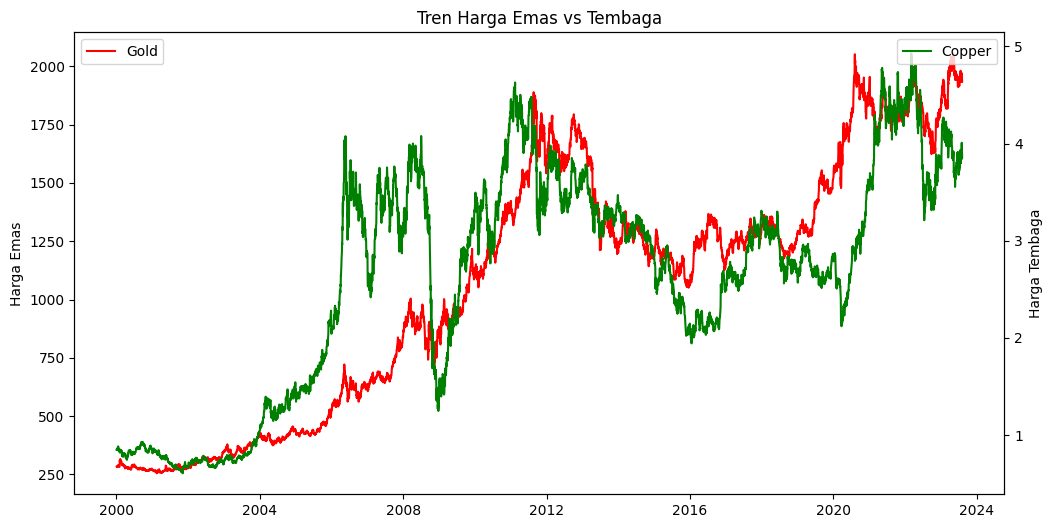

In [62]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(df_metal_clean.index, df_metal_clean['GOLD'], label='Gold', color='red')

ax2 = ax.twinx()
ax2.plot(df_metal_clean.index, df_metal_clean['COPPER'], label='Copper', color='green')

ax.set_ylabel("Gold Price")
ax2.set_ylabel("Copper Price")
ax.set_ylabel("Harga Emas"); ax2.set_ylabel("Harga Tembaga")
ax.set_title("Tren Harga Emas vs Tembaga")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")

**Interpretation:**

Menurut **saya**, grafik *"Tren Harga Emas vs Tembaga"* ini memperlihatkan bahwa dalam jangka panjang (sekitar tahun 2000 hingga 2023) harga **Gold** (merah) dan **Copper** (hijau) sama-sama punya tren naik, tetapi karakter pergerakannya berbeda saat menghadapi gejolak ekonomi.

Berikut interpretasi sederhananya menurut **saya**:

* **Tren jangka panjang sama-sama naik:**
  - Dari awal 2000-an sampai mendekati 2023, kedua komoditas ini tumbuh signifikan dari level rendah menuju kisaran yang jauh lebih tinggi.


* **Copper lebih fluktuatif / sensitif siklus ekonomi:**
  - Garis hijau (*Copper*) terlihat lebih tajam naik-turunnya—misalnya lonjakan tinggi sekitar 2006–2007 lalu anjlok cukup dalam di sekitar 2008–2009, serta turun lagi sekitar 2015–2016 dan awal 2020. Menurut **saya**, ini sejalan dengan sifat tembaga sebagai logam industri yang sangat dipengaruhi aktivitas manufaktur dan ekonomi global.


* **Gold cenderung lebih tahan banting saat tekanan:**
  - Garis merah (*Gold*) tampak lebih stabil menanjak dalam banyak fase dan sering menguat atau bertahan lebih baik saat *Copper* tertekan (seperti sekitar 2016 dan 2020).


* **Catatan pembacaan skala ganda:**
  - Karena *Gold* memakai sumbu kiri dan *Copper* memakai sumbu kanan dengan skala berbeda, perpotongan garis di grafik menunjukkan posisi relatif pada masing-masing skala, bukan berarti harga dolar per satuannya sama persis.



**Kesimpulan singkat dari saya:** grafik ini menggambarkan hubungan dinamis antara logam *safe-haven* (*Gold*) dan logam berbasis aktivitas industri (*Copper*)—sama-sama naik dalam jangka panjang, tapi *Copper* lebih bergejolak mengikuti siklus ekonomi. .

### b) Jumlah nilai hilang per kolom (sebelum dibersihkan)

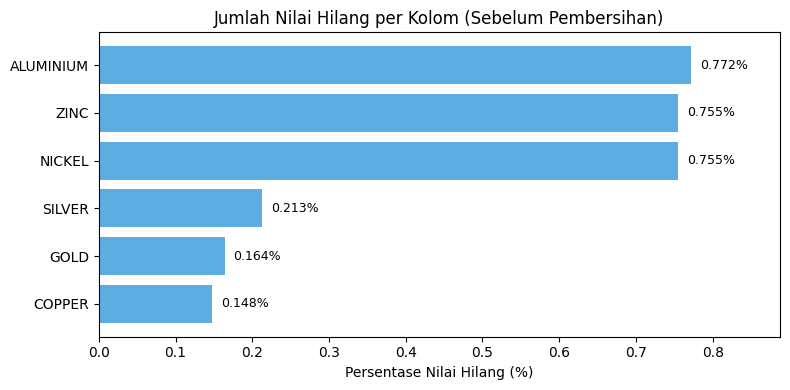

In [67]:
s = missing_val_percentage.drop("Date").sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(s.index, s.values, color="#5DADE2")

ax.set_title("Jumlah Nilai Hilang per Kolom (Sebelum Pembersihan)")
ax.set_xlabel("Persentase Nilai Hilang (%)")

# Beri ruang ekstra di kanan agar label angka tidak terpotong
ax.set_xlim(0, s.max() * 1.15)

# Tampilkan nilai persentase di sebelah kanan setiap bar
for bar in bars:
    val = bar.get_width()
    ax.text(
        val + (s.max() * 0.015),  # sedikit geser ke kanan dari ujung bar
        bar.get_y() + bar.get_height() / 2,  # tepat di tengah tinggi bar
        f"{val:.3f}%",
        va="center",
        ha="left",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Interpretation:**


Menurut **saya**, grafik batang horizontal *"Jumlah Nilai Hilang per Kolom (Sebelum Pembersihan)"* ini menampilkan perbandingan persentase *missing value* keenam logam dari yang terkecil hingga terbesar, dengan label angka yang sudah terbaca jelas di ujung tiap batang.

Berikut interpretasi sederhananya menurut **saya**:

* **Semua kolom di bawah 1%:** Persentase nilai hilang tertinggi hanya berada di `ALUMINIUM` (`0.772%`), sehingga secara keseluruhan kualitas data sebelum pembersihan sudah sangat baik.


* **Kelompok nilai hilang relatif lebih tinggi (`0.755% – 0.772%`):** `ALUMINIUM` (`0.772%`), `ZINC` (`0.755%`), dan `NICKEL` (`0.755%`) berada di urutan teratas dengan proporsi yang hampir sama. Menurut **saya**, kesamaan tingkat kekosongan ini memperkuat indikasi bahwa ketiganya memiliki pola hari libur atau sumber pencatatan yang berdekatan.


* **Kelompok nilai hilang sangat rendah (`0.148% – 0.213%`):** `SILVER` (`0.213%`), `GOLD` (`0.164%`), dan `COPPER` (`0.148%`) memiliki persentase kosong jauh lebih kecil, dengan `COPPER` sebagai logam yang paling sedikit kehilangan data.



**Kesimpulan singkat dari saya:** visualisasi ini memudahkan pembaca melihat bahwa `ALUMINIUM`, `ZINC`, dan `NICKEL` memiliki porsi *missing value* terbesar di antara keenam logam, namun angkanya tetap sangat kecil sehingga aman ditangani pada tahap *cleaning*.

### c) Volatility: distribution of daily gold returns

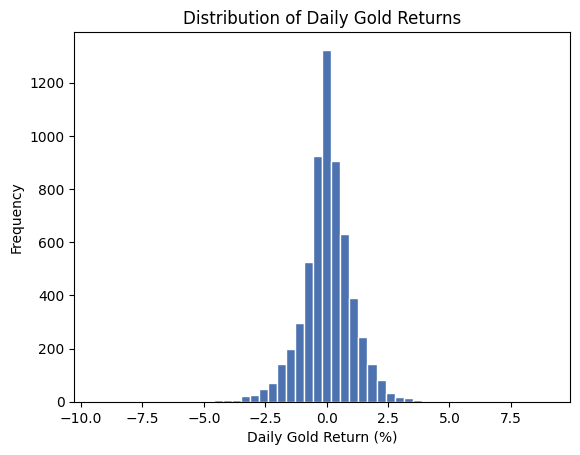

In [69]:
df_metal_clean['gold_return'] = df_metal_clean['GOLD'].pct_change() * 100

plt.hist(df_metal_clean['gold_return'].dropna(),
         bins=50,
         color="#4C72B0",
         edgecolor="white")

plt.xlabel("Daily Gold Return (%)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Gold Returns");

**Interpretation:**


Menurut **saya**, histogram *"Distribution of Daily Gold Returns"* ini menunjukkan bahwa perubahan harga harian emas paling sering berada di sekitar **0%** dengan sebaran yang cukup simetris.

Berikut interpretasi sederhananya menurut **saya**:

* **Terpusat tajam di sekitar 0%:** Batang tertinggi berada tepat di dekat titik `0` (dengan frekuensi di atas 1.300 hari), yang berarti pada mayoritas hari perdagangan perubahan harga emas tergolong kecil dan stabil.


* **Pergerakan harian normalnya sempit:** Sebagian besar data mengumpul di kisaran sekitar **-2,5% hingga +2,5%**. Menurut **saya**, ini menggambarkan pergerakan harian emas yang relatif terkendali pada kondisi pasar biasa.


* **Ekor distribusi memanjang (*fat tails* / kejadian ekstrem jarang):** Terdapat beberapa batang kecil yang memanjang hingga sekitar `-5%` atau lebih dan sekitar `+5%`. Menurut **saya**, ini menandakan lonjakan atau penurunan tajam harian memang ada, tetapi frekuensinya sangat jarang dibanding hari-hari biasa.


* **Bentuk relatif simetris:** Sisi kiri (penurunan) dan sisi kanan (kenaikan) terlihat cukup berimbang, tanpa condong ekstrem ke satu arah tertentu.



**Kesimpulan singkat dari saya:** *daily return* emas didominasi fluktuasi kecil di sekitar nol, dengan kejadian ekstrem yang jarang muncul.

## Conclusions & Insights

Berdasarkan seluruh proses pembersihan data (*data cleaning*) dan analisis awal yang telah dilakukan pada dataset harga komoditas logam, berikut adalah beberapa **kesimpulan utama dan wawasan (*insights*)** yang dapat diambil:

### 1. Kualitas Dataset Sangat Baik
* Sebelum proses pembersihan, persentase data hilang (*missing values*) pada seluruh kolom logam terpilih berada di bawah **1%**.
* Logam industri seperti **Aluminium (0.772%)**, **Seng/Zinc (0.755%)**, dan **Nikel (0.755%)** memiliki proporsi kekosongan yang serupa. Hal ini menunjukkan indikasi kuat adanya kesamaan sumber bursa atau kalender hari perdagangan.
* Kelompok logam mulia dan tembaga memiliki tingkat kekosongan yang jauh lebih kecil lagi (< 0.22%), yang merupakan batas deviasi sangat wajar dalam pencatatan data keuangan jangka panjang (sejak tahun 2000 hingga 2023).

### 2. Validitas Metode Forward-Fill (ffill)
* Pembersihan menggunakan metode *Forward-fill* sangat logis untuk data deret waktu keuangan komoditas karena menjaga harga terakhir yang terbentuk saat pasar sedang libur (akhir pekan atau libur bursa) tanpa menimbulkan kebocoran data masa depan (*data leakage*).
* Hasil pengecekan baris duplikat menunjukkan bahwa baris-baris berulang tersebut murni berasal dari akhir pekan (Jumat ke Senin) serta hari libur nasional (seperti Paskah dan akhir tahun), sehingga baris tersebut valid untuk dipertahankan guna menjaga kontinuitas deret waktu harian.

### 3. Wawasan Pasar Logam (Emas vs Tembaga)
* **Emas (GOLD)** terbukti memiliki sifat sebagai aset pelindung nilai (*safe-haven*). Pergerakan harganya cenderung naik lebih stabil dan tangguh dalam jangka panjang, bahkan ketika kondisi ekonomi global mengalami guncangan.
* **Tembaga (COPPER)** bertindak sebagai indikator aktivitas industri global (*Doc Copper*). Harganya sangat fluktuatif dan sensitif terhadap siklus ekonomi, terlihat dari koreksi tajam pada krisis 2008 dan pandemi 2020 sebelum akhirnya bangkit kembali secara signifikan.

### 4. Karakteristik Volatilitas Emas
* Distribusi perubahan harga harian (*daily returns*) Emas terpusat sangat padat di sekitar **0%** dengan rentang fluktuasi normal yang sempit antara **-2.5% hingga +2.5%**.
* Adanya ekor distribusi yang memanjang (*fat tails*) menunjukkan bahwa lonjakan ekstrem (baik kenaikan maupun penurunan tajam di atas 5%) tetap terjadi, namun dalam frekuensi historis yang sangat langka.

Dengan tuntasnya tahap pembersihan dan pemahaman karakteristik data ini, dataset `df_metal_clean` kini telah **sepenuhnya siap** untuk digunakan pada tahap pemodelan prediksi (*forecasting*), analisis korelasi tingkat lanjut, maupun pembuatan keputusan investasi industri tambang.
